# Handwritten Digit Recognition with Error Analysis

**Family:** End-to-end project | **Dataset:** `digits` | **Task:** classification

Compare five classifiers, study the errors, and test robustness to noise.

## Table of Contents

- 1. Problem statement
- 2. Business or research context
- 3. Dataset documentation
- 4. Research references
- 5. Exploratory analysis
- 6. Preprocessing
- 7. Model selection
- 8. Model training
- 9. Evaluation
- 10. Comparison
- 11. Interpretation
- 12. Limitations
- 13. Final recommendations

## 1. Problem statement

Recognise handwritten digits from 8 by 8 pixel images and find out which digits get confused and how robust the model is.

## 2. Business or research context

Form processing and cheque reading depend on reliable digit recognition. Overall accuracy hides which digits fail, and clean test images hide fragility to noise.

## 3. Dataset documentation

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

## 4. Research references

Verification status is from the build environment on 2026-11-17. Entries marked *not verified* must be checked before citing.

- Cortes, C. and Vapnik, V. (1995). *Support-vector networks*. Machine Learning 20(3):273-297. https://doi.org/10.1007/BF00994018 Verification: Crossref 2026-11-17
- Breiman, L. (2001). *Random Forests*. Machine Learning 45(1):5-32. https://doi.org/10.1023/A:1010933404324 Verification: Crossref 2026-11-17
- Cover, T. and Hart, P. (1967). *Nearest neighbor pattern classification*. IEEE Transactions on Information Theory 13(1):21-27. https://doi.org/10.1109/TIT.1967.1053964 Verification: Crossref 2026-11-17

Support vector machines, random forests and nearest neighbours are compared with a neural network.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline, build_preprocessor
from ml_lab.evaluation import evaluate_estimator, internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
PROJECT_ID = "digit_recognition"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("digits")
X, y = bundle.X, bundle.y
Xtr, Xva, Xte, ytr, yva, yte = split_three_way(X, y, task="classification", seed=SEED)
print(len(Xtr), len(Xva), len(Xte))

1077 360 360


## 5. Exploratory analysis

Example images and class balance.

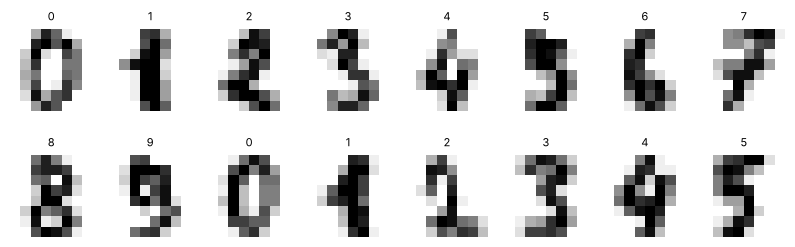

{0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


In [3]:
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(X.values[i].reshape(8, 8), cmap="gray_r"); ax.set_title(int(y.iloc[i]), fontsize=8); ax.axis("off")
plt.show(); print(y.value_counts().sort_index().to_dict())

## 6. Preprocessing

Pixel values are divided by 16 inside the scaler step. No other preprocessing.

In [4]:
print("pixel range:", X.values.min(), "to", X.values.max())

pixel range: 0.0 to 16.0


## 7. Model selection

Logistic regression, k nearest neighbours, RBF SVM, random forest and a small neural network. Chosen by validation macro F1.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score
cands = {"logistic": LogisticRegression(max_iter=3000), "knn": KNeighborsClassifier(3), "svm_rbf": SVC(C=10, gamma="scale"), "random_forest": RandomForestClassifier(300, n_jobs=2, random_state=SEED),
         "mlp": MLPClassifier((64,), alpha=1e-3, max_iter=500, early_stopping=True, random_state=SEED)}
fitted = {n: make_model_pipeline(Xtr, m).fit(Xtr, ytr) for n, m in cands.items()}
sel = pd.Series({n: f1_score(yva, f.predict(Xva), average="macro") for n, f in fitted.items()}, name="validation macro F1")
display(sel.round(4).to_frame()); BEST = sel.idxmax(); print("selected:", BEST)

,validation macro F1
logistic,0.9724
knn,0.9640
svm_rbf,0.9916
random_forest,0.9779
mlp,0.9470


selected: svm_rbf


## 8. Model training

Refit the selected model on training plus validation rows.

In [6]:
Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
final = make_model_pipeline(Xtv, clone(cands[BEST])).fit(Xtv, ytv)
cv = cross_val_score(make_model_pipeline(Xtv, clone(cands[BEST])), Xtv, ytv, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1_macro")
print(f"CV macro F1 {cv.mean():.4f} +- {cv.std(ddof=1):.4f}")

CV macro F1 0.9826 +- 0.0080


## 9. Evaluation

Test set, scored once, with the dummy baseline (most frequent class).

In [7]:
pred = final.predict(Xte)
base = DummyClassifier(strategy="prior").fit(Xtr, ytr)
METRICS = {"test_accuracy": float((pred == yte).mean()), "test_macro_F1": f1_score(yte, pred, average="macro"), "baseline_accuracy": float((base.predict(Xte) == yte).mean()),
           "cv_macro_F1_mean": float(cv.mean()), "cv_macro_F1_std": float(cv.std(ddof=1))}
CONFIG = {"selected_model": BEST}
EXTRA = {"validation_macro_F1": sel.round(4).to_dict(), "test_rows": int(len(yte))}
ALGORITHM = BEST

record = ExperimentRecord(notebook=PROJECT_ID, family="project", algorithm=ALGORITHM, dataset="digits", task="classification", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: /home/claude/open-python/experiments/results/digit_recognition.json


,metric
test_accuracy,0.9806
test_macro_F1,0.9805
baseline_accuracy,0.1000
cv_macro_F1_mean,0.9826
cv_macro_F1_std,0.0080


## 10. Comparison

All five models on the test rows, for comparison only.

In [8]:
display(pd.Series({n: f1_score(yte, f.predict(Xte), average="macro") for n, f in fitted.items()}, name="test macro F1").round(4).to_frame())

,test macro F1
logistic,0.9577
knn,0.9688
svm_rbf,0.9804
random_forest,0.9579
mlp,0.9376


## 11. Interpretation

Which digit pairs are confused, and a picture of the errors. Then robustness to Gaussian noise added to the test pixels.

most frequent confusions (count, true, predicted): [(np.int64(1), 9, 7), (np.int64(1), 9, 6), (np.int64(1), 8, 4), (np.int64(1), 8, 1), (np.int64(1), 7, 5)]


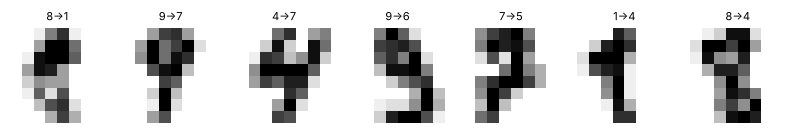

noise std 0: accuracy 0.981
noise std 1: accuracy 0.153
noise std 2: accuracy 0.111
noise std 4: accuracy 0.100


In [9]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yte, pred); np.fill_diagonal(cm, 0)
pairs = sorted([(cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j] > 0], reverse=True)[:5]
print("most frequent confusions (count, true, predicted):", pairs)
wrong = np.where(pred != yte.values)[0][:8]
fig, axes = plt.subplots(1, max(1, len(wrong)), figsize=(10, 1.8))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(Xte.values[i].reshape(8, 8), cmap="gray_r"); ax.set_title(f"{yte.values[i]}->{pred[i]}", fontsize=8); ax.axis("off")
plt.show()
rng = np.random.default_rng(SEED)
for sd in [0, 1, 2, 4]:
    noisy_X = np.clip(Xte.values + rng.normal(0, sd, Xte.shape), 0, 16)
    print(f"noise std {sd}: accuracy {(final.predict(pd.DataFrame(noisy_X, columns=Xte.columns)) == yte.values).mean():.3f}")

## 12. Limitations

8 by 8 images from one collection, 1797 rows. High accuracy here does not transfer to different writers, scanners or larger images.

## 13. Final recommendations

Use SVM or a small network as a baseline for small digit images, always review the confusion pairs, and test on noisy and shifted images before any deployment.